# 문제 정형화와 평가지표 실습: 문제를 직접 정해 보기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week01/2_problem_formulation/lab/problem_formulation.ipynb)

모델보다 먼저 **다섯 칸** 을 채운다: ① 한 행은 무엇? ② 입력 X ③ 출력 y ④ 평가지표 ⑤ 기준선.

- **파트 1**: 같은 공, 두 문제: 던지기 전에 타자가 스윙할까 (분류) · 이 공의 구속 (회귀), 정확도 · MAE · 기준선 직접 만들기
- **파트 2**: 6월의 모든 공: 정확도의 함정, 볼카운트 규칙의 정밀도 · 재현율, 한 행을 공 → 타석 → 타자로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 코드 칸 아래의 **예상 결과** 와 비교하면 맞았는지 바로 알 수 있습니다.

In [ ]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

## 파트 1. 같은 공, 두 문제

먼저 채점 함수 세 개를 만든다. 정답 `y_true` 와 예측 `y_pred` 를 받는다.
- 정확도 = 맞힌 개수 ÷ 전체
- MAE = 오차 절댓값의 평균
- RMSE = 오차 제곱의 평균에 루트

In [ ]:
def accuracy(y_true, y_pred):
    return None   # TODO: fraction of exact matches

def mae(y_true, y_pred):
    return None   # TODO: mean of |error|

def rmse(y_true, y_pred):
    return None   # TODO: sqrt of mean of error^2

print("accuracy:", accuracy([0, 1, 2, 2], [0, 1, 1, 2]))          # 0.75
print("MAE :", mae([0, 0, 0, 0], [1, 1, 1, 9]))                  # slide: 3
print("RMSE:", round(rmse([0, 0, 0, 0], [1, 1, 1, 9]), 2))       # slide: 4.58

**예상 결과**

```
accuracy: 0.75
MAE : 3.0
RMSE: 4.58
```

2024년 6월 MLB 정규시즌에 던진 **모든 공** 을 Baseball Savant (MLB Statcast) 에서 받는다. 한 행 = 공 하나 (투구). 한 번에 25,000줄까지만 주니 5일씩 6번 받는다. 로그인 없이 받을 수 있고, 처음엔 4~5분 걸린다. 파트 1 과 파트 2 가 이 데이터를 같이 쓴다.

- `balls`, `strikes`: **던지기 직전** 볼카운트, `pitch_type`, `release_speed`: 구종 · 구속 (mph)
- `description`: 그 공의 결과 (`ball`, `swinging_strike`, `hit_into_play` …), `events`: 타석이 끝났으면 그 결과 (`home_run`, `single`, `field_out` …)
- `batter`, `pitcher`: 타자 · 투수 번호. 인플레이 타구에는 `launch_speed` · `launch_angle` · `hit_distance_sc` (타구 속도 · 발사각 · 비거리) 도 있다

In [ ]:
os.makedirs("data", exist_ok=True)
SAVANT = ("https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=batter"
          "&hfGT=R%7C&hfSea=2024%7C&game_date_gt={}&game_date_lt={}")
CHUNKS = [("01", "05"), ("06", "10"), ("11", "15"), ("16", "20"), ("21", "25"), ("26", "30")]
COLS = ["game_date", "game_pk", "at_bat_number", "pitch_number", "batter", "pitcher", "player_name", "balls", "strikes",
        "pitch_type", "release_speed", "description", "events", "launch_speed", "launch_angle", "hit_distance_sc"]

def load_pitches(chunks):
    parts = []
    for a, b in chunks:
        path = f"data/pitches_2024-06-{a}.csv"
        if not os.path.exists(path):
            req = urllib.request.Request(SAVANT.format(f"2024-06-{a}", f"2024-06-{b}"), headers={"User-Agent": "book-ml-course"})
            with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
                f.write(r.read())
        parts.append(pd.read_csv(path, usecols=COLS))
    return pd.concat(parts, ignore_index=True)

pitches = load_pitches(CHUNKS)
pitches["home_run"] = (pitches["events"] == "home_run").astype(int)
print(pitches.shape, " home runs:", pitches["home_run"].sum())
pitches[["game_date", "player_name", "balls", "strikes", "pitch_type", "description", "events"]].head(3)

**예상 결과**

```
(116355, 17)  home runs: 921
    game_date    player_name  balls  strikes pitch_type    description  \
0  2024-06-05  Pillar, Kevin      1        2         FF  hit_into_play   
1  2024-06-05  Pillar, Kevin      0        2         FF           ball   
2  2024-06-05  Pillar, Kevin      0        1         FF  called_strike   

      events  
0  field_out  
1        NaN  
2        NaN  
```

파트 1 에서는 **공을 던지기 직전** 에 알 수 있는 것만 입력으로 쓴다: 볼카운트 (`count`), 타자 (`batter`), 투수 (`pitcher`). 한 행 = 공 하나. 구속 · 구종이 비어 있는 공은 뺀다.

- 출력 A: 타자가 이 공에 **스윙했나** (헛스윙 · 파울 · 인플레이 = 1, 그 밖 = 0)
- 출력 B: 이 공의 **구속** (km/h)

시험 데이터는 **날짜 순서** 로 나눈다: 6월 1~23일로 학습, 24~30일로 시험 (앞으로 열릴 경기를 맞히는 상황).

In [ ]:
SWING = {"hit_into_play", "foul", "swinging_strike", "swinging_strike_blocked", "foul_tip", "foul_bunt", "missed_bunt", "bunt_foul_tip"}
df = pitches.dropna(subset=["release_speed", "pitch_type"]).copy()
df["count"] = df["balls"].astype(str) + "-" + df["strikes"].astype(str)
df["swing"] = df["description"].isin(SWING).astype(int)
df["kmh"] = df["release_speed"] * 1.609
train = None   # TODO: pitches on or before 2024-06-23
test = None    # TODO: pitches on or after 2024-06-24
print("rows:", len(df), " train:", len(train), " test:", len(test))
print("swing rate:", round(df["swing"].mean(), 3))
df[["game_date", "count", "batter", "pitcher", "swing", "kmh"]].head(3)

**예상 결과**

```
rows: 115940  train: 88024  test: 27916
swing rate: 0.482
    game_date count  batter  pitcher  swing       kmh
0  2024-06-05   1-2  607680   656302      1  157.3602
1  2024-06-05   0-2  607680   656302      0  157.6820
2  2024-06-05   0-1  607680   656302      0  156.0730
```

### 문제 A: 던지기 전 정보 → 타자가 스윙할까 (분류)

입력은 숫자가 아니라 **이름표** (볼카운트 `3-2`, 타자 번호, 투수 번호) 라서 원-핫 (one-hot) 으로 바꿔 넣는다: 칸마다 '이 이름표인가' 를 0/1 로 적는 것. **기준선** = 늘 '안 친다' 라고 답하기.

In [ ]:
INPUTS = ["count", "batter", "pitcher"]

def fit_classifier(train_df, cols):
    model = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=2000))
    return model.fit(train_df[cols].astype(str), train_df["swing"])

base_pred = np.zeros(len(test), dtype=int)          # always 'no swing'
only_count = fit_classifier(train, ["count"])
clf = None   # TODO: fit_classifier with all three inputs
print(f"baseline (always 'no swing'): accuracy {accuracy(test['swing'], base_pred):.1%}")
print(f"count only                  : accuracy {accuracy(test['swing'], only_count.predict(test[['count']].astype(str))):.1%}")
print(f"count + batter + pitcher    : accuracy {accuracy(test['swing'], clf.predict(test[INPUTS].astype(str))):.1%}")

**예상 결과**

```
baseline (always 'no swing'): accuracy 51.4%
count only                  : accuracy 59.6%
count + batter + pitcher    : accuracy 60.3%
```

### 문제 B: 같은 공, 같은 입력 → 구속 (회귀)

이번엔 `y` 가 구속 (km/h). 입력은 문제 A 와 같다. **기준선** = 학습 데이터의 평균 구속을 늘 답하기.

In [ ]:
def fit_regressor(train_df, cols):
    model = make_pipeline(OneHotEncoder(handle_unknown="ignore"), Ridge(alpha=1.0))
    return model.fit(train_df[cols].astype(str), train_df["kmh"])

mean_kmh = train["kmh"].mean()
base_pred = None   # TODO: the training mean, repeated for every test pitch
reg = fit_regressor(train, INPUTS)
print(f"baseline (always {mean_kmh:.1f} km/h): MAE {mae(test['kmh'], base_pred):.1f}  RMSE {rmse(test['kmh'], base_pred):.1f}")
print(f"count + batter + pitcher     : MAE {mae(test['kmh'], reg.predict(test[INPUTS].astype(str))):.1f}  RMSE {rmse(test['kmh'], reg.predict(test[INPUTS].astype(str))):.1f}")

**예상 결과**

```
baseline (always 143.6 km/h): MAE 8.0  RMSE 9.5
count + batter + pitcher     : MAE 7.3  RMSE 8.5
```

### 반칙 하나: 구종을 입력에 넣으면?

구종 (`pitch_type`: 직구 FF, 슬라이더 SL …) 은 **공을 던진 뒤에야** 안다. 그래도 넣어 보자.

In [ ]:
leak = fit_regressor(train, INPUTS + ["pitch_type"])
print(f"+ pitch type (cheating): MAE {mae(test['kmh'], leak.predict(test[INPUTS + ['pitch_type']].astype(str))):.1f}")

**예상 결과**

```
+ pitch type (cheating): MAE 2.3
```

**생각해 보기**: 구종을 넣으면 MAE 가 크게 줄어든다. 이 숫자를 보고서에 쓰면 안 되는 이유는? 그리고 문제 A 에서 볼카운트만으로 정확도가 많이 오른 이유를, 볼카운트별 스윙 비율 (`df.groupby("count")["swing"].mean()`) 을 찍어 보고 말해 보자.

## 파트 2. 6월의 모든 공: 정확도의 함정

파트 1 에서 받은 `pitches` 를 그대로 쓴다. **한 행 = 공 하나**, 출력 `y` = 이 공이 홈런이 되었나 (0/1). 먼저 한 타석이 공 여러 개로 이루어진다는 걸 보자: 6월 오타니의 첫 홈런 타석을 공 단위로 펼친다.

In [ ]:
OHTANI = 660271
oh_hr = pitches[(pitches["batter"] == OHTANI) & (pitches["home_run"] == 1)].sort_values(["game_date", "at_bat_number"])
game, at_bat = oh_hr.iloc[0][["game_pk", "at_bat_number"]]
one_pa = pitches[(pitches["game_pk"] == game) & (pitches["at_bat_number"] == at_bat)].sort_values("pitch_number")
one_pa[["game_date", "pitch_number", "balls", "strikes", "pitch_type", "release_speed", "description", "events", "home_run"]]

**예상 결과**

```
       game_date  pitch_number  balls  strikes pitch_type  release_speed  \
1067  2024-06-05             1      0        0         FF           99.6   
1026  2024-06-05             2      0        1         CH           86.9   
1005  2024-06-05             3      1        1         CH           88.1   
958   2024-06-05             4      2        1         FF           99.5   
934   2024-06-05             5      2        2         FF          100.0   
909   2024-06-05             6      3        2         FF          100.1   

          description    events  home_run  
1067  swinging_strike       NaN         0  
1026             ball       NaN         0  
1005     blocked_ball       NaN         0  
958   swinging_strike       NaN         0  
934              ball       NaN         0  
909     hit_into_play  home_run         1  
```

In [ ]:
y = pitches["home_run"].values
print("pitches:", len(y), "  home runs:", y.sum(), f"({y.mean():.2%})")

all_no = None   # TODO: predict 0 (no HR) for every pitch
print(f"'always no HR' accuracy: {accuracy(y, all_no):.2%}")

**예상 결과**

```
pitches: 116355   home runs: 921 (0.79%)
'always no HR' accuracy: 99.21%
```

정확도가 매우 높지만 홈런을 하나도 못 잡는다. **던지기 직전 볼카운트** 는 예측하는 순간 알 수 있는 입력이다. 볼카운트별로 홈런이 된 공의 비율을 보자.

In [ ]:
pitches["count"] = pitches["balls"].astype(str) + "-" + pitches["strikes"].astype(str)
by_count = pitches.groupby("count")["home_run"].agg(["mean", "sum", "size"]).sort_values("mean")
print(by_count)
plt.figure(figsize=(7, 3)); plt.bar(by_count.index, by_count["mean"] * 100, color="gray")
plt.axhline(y.mean() * 100, color="navy", ls=":"); plt.xlabel("count before the pitch (balls-strikes)"); plt.ylabel("HR on this pitch (%)"); plt.show()

**예상 결과**

```
           mean  sum   size
count                      
3-0    0.003591    4   1114
0-2    0.004475   36   8044
0-0    0.006088  183  30060
0-1    0.006533  100  15308
1-2    0.007111   81  11391
1-1    0.008557  100  11686
1-0    0.008571   96  11201
2-2    0.008926   86   9635
2-0    0.009623   36   3741
2-1    0.012195   73   5986
3-1    0.014969   36   2405
3-2    0.015560   90   5784
```

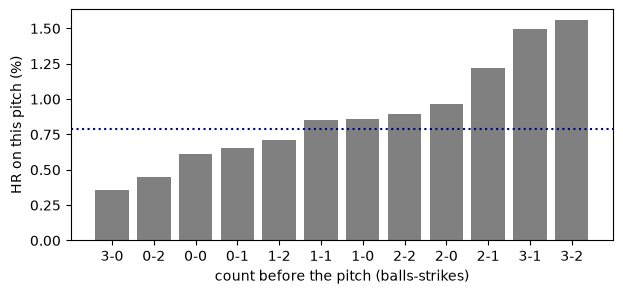

규칙 하나를 만들어 보자: **볼카운트가 3-1 또는 3-2 이면 '홈런'**.

In [ ]:
rule = None   # TODO: 1 if the count is 3-1 or 3-2, else 0
print(f"rule accuracy: {accuracy(y, rule):.2%}")

**예상 결과**

```
rule accuracy: 92.39%
```

### 정밀도와 재현율: 세는 법을 바꾼다

- **재현율** = 잡았다 ÷ 실제 홈런 전부 (실제 홈런 중 몇 개를 잡았나)
- **정밀도** = 잡았다 ÷ '홈런' 이라고 한 것 전부 (찍은 것 중 진짜는 몇 개)

(3주차 정밀도와 재현율에서 자세히 다룬다.)

In [ ]:
def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))     # caught
    fp = np.sum((y_pred == 1) & (y_true == 0))     # false alarm
    fn = np.sum((y_pred == 0) & (y_true == 1))     # missed
    precision = None   # TODO: caught / everything we called HR
    recall = None      # TODO: caught / all real HRs
    return tp, fp, fn, precision, recall

for name, pred in [("always no HR", all_no), ("rule: count 3-1 / 3-2", rule)]:
    tp, fp, fn, p, r = precision_recall(y, pred)
    print(f"{name:22s} caught {tp:4d}  false alarms {fp:6d}  missed {fn:4d}  precision {p:.2%}  recall {r:.1%}")

**예상 결과**

```
always no HR           caught    0  false alarms      0  missed  921  precision 0.00%  recall 0.0%
rule: count 3-1 / 3-2  caught  126  false alarms   8063  missed  795  precision 1.54%  recall 13.7%
```

### 한 행 = 공 → 타석 → 타자

같은 6월 기록으로 한 행을 바꿔 보자. 타석은 `game_pk` + `at_bat_number` 로 묶고 **홈런으로 끝났으면 1**, 타자는 `batter` 로 묶고 **6월에 홈런을 한 번이라도 쳤으면 1**.

In [ ]:
pa_y = None   # TODO: per plate appearance (game_pk, at_bat_number), 1 if any pitch was a HR
batter_y = None   # TODO: per batter, 1 if they hit any HR in June
print(f"pitch : {len(y):6d} rows  HR rate {y.mean():.2%}")
print(f"PA    : {len(pa_y):6d} rows  HR rate {pa_y.mean():.2%}   ({len(y) / len(pa_y):.2f} pitches per PA)")
print(f"batter: {len(batter_y):6d} rows  HR rate {batter_y.mean():.1%}")

**예상 결과**

```
pitch : 116355 rows  HR rate 0.79%
PA    :  30060 rows  HR rate 3.06%   (3.87 pitches per PA)
batter:    480 rows  HR rate 64.6%
```

**관찰**: 같은 기록인데 한 행을 무엇으로 정하느냐에 따라 '홈런 비율' 이 0.79% → 3.06% → 64.6% 로 바뀐다. 볼카운트를 입력으로 쓸 수 있는 것도 한 행이 공 하나일 때뿐이다 (타석이 시작될 땐 늘 0-0).

**생각해 보기**: 한 행 = 타석 하나로 '이 타석이 홈런으로 끝날까?' 를 타석 시작 전에 맞힌다면, 입력으로 쓸 수 있는 것은 무엇일까?

**확인 질문**
1. 파트 1 문제 A 에서 정확도가 기준선보다 1.3%p 높다. 이 모델은 쓸 만한가? 홈런을 몇 개 잡았는지로 말해 보자.
2. 파트 2 에서 모든 공에 '홈런' 이라고 답하면 재현율과 정밀도는 각각 얼마가 될까?
3. 파트 2 의 볼카운트 규칙에 '작년 30홈런 이상 타자' 같은 조건을 더하면 정밀도와 재현율은 어떻게 바뀔까?
4. 공 하나를 한 행으로 학습 · 시험을 나눌 때, 무작위로 섞으면 무엇이 문제일까? (힌트: 같은 타석의 바로 앞뒤 공)

데이터 출처: Baseball Savant (MLB Statcast).